In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
n = 480

# Her yaş grubunda 160 kurgusal katılımcı
yas_grubu = rng.permutation(np.repeat(["18-19", "20-21", "22-23"], 160))
calisma_durumu = rng.choice(["Çalışıyor", "Çalışmıyor"], size=n, p=[0.40, 0.60])

# Üç ilişkili boyut: hangi özellik, neden, davranışa yansıma
boyutlar = rng.multivariate_normal(
    mean=[0, 0, 0],
    cov=[
        [1.00, 0.35, 0.35],
        [0.35, 1.00, 0.35],
        [0.35, 0.35, 1.00],
    ],
    size=n,
)

veri = pd.DataFrame({
    "ID": np.arange(1, n + 1),
    "Yas_Grubu": yas_grubu,
    "Calisma_Durumu": calisma_durumu,
})

# M01–M10: hangi özellikler, M11–M20: neden, M21–M30: davranış
madde_sutunlari = []

for boyut in range(3):
    for madde in range(10):
        ad = f"M{boyut * 10 + madde + 1:02d}"
        madde_sutunlari.append(ad)

        yanit_duzeyi = (
            rng.uniform(0.75, 1.00) * boyutlar[:, boyut]
            + rng.uniform(-0.30, 0.30)
            + rng.normal(0, 0.65, size=n)
        )
        veri[ad] = np.digitize(yanit_duzeyi, [-1.2, -0.4, 0.4, 1.2]) + 1

# Kurgu varsayımı: netliği daha düşük olanlarda bu deneyimi
# bildirme olasılığı biraz daha yüksek.
# 1 = kendi tercihiyle çevre beklentisi arasında kaldı, 0 = kalmadı
logit = -0.20 - 0.30 * boyutlar[:, 0] - 0.35 * boyutlar[:, 1] - 0.20 * boyutlar[:, 2]
olasilik = 1 / (1 + np.exp(-logit))
veri["Tercih_Catismasi"] = rng.binomial(1, olasilik)

assert veri[madde_sutunlari].isin([1, 2, 3, 4, 5]).all().all()
assert veri["Tercih_Catismasi"].nunique() == 2

dosya = Path("vize_anket_verisi.csv").resolve()
veri.to_csv(dosya, index=False, encoding="utf-8-sig")

print("Veri boyutu:", veri.shape)
print("Eksik değer sayısı:", veri.isna().sum().sum())
print("0/1 grup sayıları:")
print(veri["Tercih_Catismasi"].value_counts().sort_index())
print("CSV dosyası:", dosya)

Veri boyutu: (480, 34)
Eksik değer sayısı: 0
0/1 grup sayıları:
Tercih_Catismasi
0    277
1    203
Name: count, dtype: int64
CSV dosyası: C:\Users\Lenovo\Desktop\Vize_Analiz\vize_anket_verisi.csv


In [2]:
from IPython.display import display

for sutun, baslik in [
    ("Yas_Grubu", "Yaş grubu"),
    ("Calisma_Durumu", "Çalışma durumu"),
    ("Tercih_Catismasi", "Tercih çatışması"),
]:
    sayi = veri[sutun].value_counts().sort_index()
    tablo = sayi.rename("Sayı").to_frame()
    tablo["Yüzde (%)"] = (100 * sayi / len(veri)).round(1)
    tablo.index.name = baslik

    if sutun == "Tercih_Catismasi":
        tablo = tablo.rename(index={0: "Yaşamadı", 1: "Yaşadı"})

    display(tablo)

print("Anket maddelerinin betimsel istatistikleri")
madde_ozeti = veri[madde_sutunlari].agg(["mean", "std", "min", "max"]).T
madde_ozeti.columns = ["Ortalama", "Standart sapma", "En düşük", "En yüksek"]
display(madde_ozeti.round(2))

,Sayı,Yüzde (%)
Yaş grubu,,
18-19,160,33.3
20-21,160,33.3
22-23,160,33.3


,Sayı,Yüzde (%)
Çalışma durumu,,
Çalışmıyor,307,64.0
Çalışıyor,173,36.0


,Sayı,Yüzde (%)
Tercih çatışması,,
Yaşamadı,277,57.7
Yaşadı,203,42.3


Anket maddelerinin betimsel istatistikleri


,Ortalama,Standart sapma,En düşük,En yüksek
M01,2.84,1.19,1.0,5.0
M02,2.89,1.23,1.0,5.0
M03,3.11,1.26,1.0,5.0
M04,2.74,1.21,1.0,5.0
M05,3.29,1.28,1.0,5.0
M06,3.00,1.24,1.0,5.0
M07,2.93,1.22,1.0,5.0
M08,2.76,1.26,1.0,5.0
M09,3.08,1.18,1.0,5.0
M10,3.21,1.26,1.0,5.0


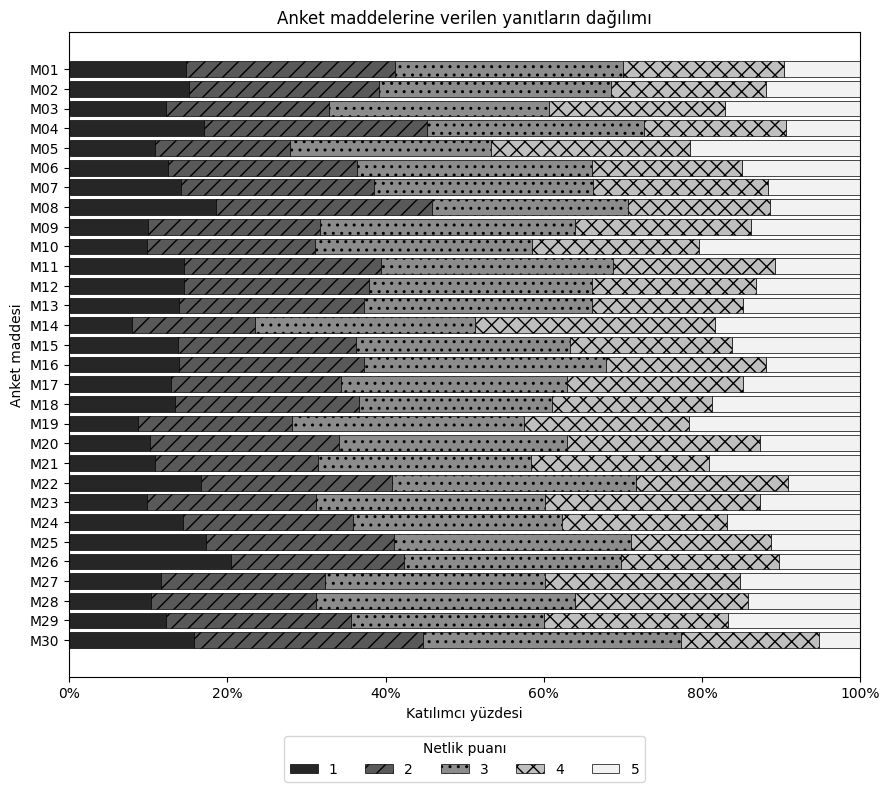

3. seçeneğin en sık seçildiği madde: M28 (%32.7)


In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

yanit_yuzdeleri = (
    veri[madde_sutunlari]
    .apply(lambda madde: madde.value_counts(normalize=True))
    .reindex([1, 2, 3, 4, 5])
    .fillna(0)
    .T.mul(100)
)

fig, ax = plt.subplots(figsize=(9, 8))
sol = np.zeros(len(yanit_yuzdeleri))

renkler = ["0.15", "0.35", "0.55", "0.75", "0.95"]
taramalar = ["", "//", "..", "xx", ""]

for puan, renk, tarama in zip(range(1, 6), renkler, taramalar):
    yuzdeler = yanit_yuzdeleri[puan]
    ax.barh(
        yanit_yuzdeleri.index, yuzdeler, left=sol,
        color=renk, edgecolor="black", linewidth=0.5,
        hatch=tarama, label=str(puan),
    )
    sol += yuzdeler.to_numpy()

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel("Katılımcı yüzdesi")
ax.set_ylabel("Anket maddesi")
ax.set_title("Anket maddelerine verilen yanıtların dağılımı")
ax.legend(title="Netlik puanı", ncol=5, loc="upper center",
          bbox_to_anchor=(0.5, -0.08))

fig.tight_layout()
fig.savefig("sekil_1_madde_yanitlari.png", dpi=300, bbox_inches="tight")
plt.show()

en_cok_3 = yanit_yuzdeleri[3].idxmax()
print(f"3. seçeneğin en sık seçildiği madde: {en_cok_3} "
      f"(%{yanit_yuzdeleri.loc[en_cok_3, 3]:.1f})")

In [6]:
import numpy as np
import pandas as pd
from IPython.display import display
from factor_analyzer.factor_analyzer import (
    calculate_kmo,
    calculate_bartlett_sphericity,
)

# Yalnızca 30 anket maddesini kullan.
maddeler = veri[madde_sutunlari]

madde_kmo, genel_kmo = calculate_kmo(maddeler)
bartlett_ki2, bartlett_p = calculate_bartlett_sphericity(maddeler)

madde_sayisi = maddeler.shape[1]
sd = madde_sayisi * (madde_sayisi - 1) // 2
p_metni = "< 0.001" if bartlett_p < 0.001 else f"= {bartlett_p:.3f}"

print(f"Genel KMO = {genel_kmo:.3f}")
print(f"En düşük madde KMO = {madde_kmo.min():.3f}")
print(f"Bartlett: χ²({sd}) = {bartlett_ki2:.2f}, p {p_metni}")

# Paralel analiz: gözlenen özdeğerleri rastgele eşiklerle karşılaştır.
rng_paralel = np.random.default_rng(42)
gozlenen = np.linalg.eigvalsh(maddeler.corr())[::-1]

rastgele_ozdegerler = []
for _ in range(500):
    karisik = np.column_stack([
        rng_paralel.permutation(sutun) for sutun in maddeler.to_numpy().T
    ])
    korelasyon = np.corrcoef(karisik, rowvar=False)
    rastgele_ozdegerler.append(np.linalg.eigvalsh(korelasyon)[::-1])

esik = np.percentile(rastgele_ozdegerler, 95, axis=0)
ilk_gecemeyen = np.flatnonzero(gozlenen <= esik)
boyut_sayisi = int(ilk_gecemeyen[0]) if ilk_gecemeyen.size else madde_sayisi

print(f"Paralel analizin önerdiği boyut sayısı: {boyut_sayisi}")
display(pd.DataFrame({
    "Sıra": np.arange(1, 7),
    "Gözlenen özdeğer": gozlenen[:6],
    "Rastgele %95 eşiği": esik[:6],
}).round(3))

Genel KMO = 0.961
En düşük madde KMO = 0.949
Bartlett: χ²(435) = 9519.46, p < 0.001
Paralel analizin önerdiği boyut sayısı: 3


,Sıra,Gözlenen özdeğer,Rastgele %95 eşiği
0,1,10.630,1.555
1,2,4.363,1.477
2,3,4.148,1.418
3,4,0.615,1.364
4,5,0.576,1.325
5,6,0.561,1.290


In [5]:
%pip install factor_analyzer

     ---------------------------------------- 0.0/42.8 kB ? eta -:--:--
     ------------------ ------------------- 20.5/42.8 kB 330.3 kB/s eta 0:00:01
     --------------------------- ---------- 30.7/42.8 kB 262.6 kB/s eta 0:00:01
     -------------------------------------- 42.8/42.8 kB 298.9 kB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/72/8d/27c054166bac671770d1ea0ef7716134fe8119c0df224a58c89fd735a61c/scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for joblib>=1.4.0 from https://files.pythonhosted.org/packages/18/53/84099323c2ec4be98d935f63c033ac4151ee


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import sklearn
print(sklearn.__version__)
print(sklearn.__file__)

1.5.2
c:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\__init__.py


In [4]:
import pandas as pd
from IPython.display import display
from factor_analyzer import FactorAnalyzer

veri = pd.read_csv("vize_anket_verisi.csv")
madde_sutunlari = [f"M{i:02d}" for i in range(1, 31)]
maddeler = veri[madde_sutunlari]

# Paralel analiz sonucuna göre üç faktör.
boyut_sayisi = 3
afa = FactorAnalyzer(n_factors=boyut_sayisi, method="minres", rotation="oblimin")
afa.fit(maddeler)

faktor_adlari = [f"Faktör {i}" for i in range(1, boyut_sayisi + 1)]
yukler = pd.DataFrame(afa.loadings_, index=madde_sutunlari, columns=faktor_adlari)
yukler.index.name = "Madde"

print("Faktör yükleri")
display(yukler.assign(
    **{"En güçlü faktör": yukler.abs().idxmax(axis=1)}
).round(3))

print("Faktörler arası korelasyonlar")
display(pd.DataFrame(
    afa.phi_, index=faktor_adlari, columns=faktor_adlari
).round(3))

Faktör yükleri


,Faktör 1,Faktör 2,Faktör 3,En güçlü faktör
Madde,,,,
M01,0.031,0.767,-0.005,Faktör 2
M02,-0.035,0.788,-0.011,Faktör 2
M03,-0.019,0.794,-0.037,Faktör 2
M04,0.032,0.733,0.006,Faktör 2
M05,-0.008,0.810,0.034,Faktör 2
M06,0.050,0.777,-0.025,Faktör 2
M07,-0.032,0.766,0.047,Faktör 2
M08,0.017,0.776,-0.014,Faktör 2
M09,0.016,0.749,-0.002,Faktör 2


Faktörler arası korelasyonlar


,Faktör 1,Faktör 2,Faktör 3
Faktör 1,1.000,0.33,0.362
Faktör 2,0.330,1.00,0.350
Faktör 3,0.362,0.35,1.000


In [5]:
# Her 10 maddelik grupta en güçlü yüklerin aynı faktörde
# toplanıp toplanmadığını kontrol et.
alt_olcekler = {
    "Hangi özellikleri geliştirmek istediğini bilme": madde_sutunlari[:10],
    "Bu özellikleri neden geliştirmek istediğini bilme": madde_sutunlari[10:20],
    "Bu özelliklerin davranışa nasıl yansıyacağını bilme": madde_sutunlari[20:],
}

en_guclu_faktor = yukler.abs().idxmax(axis=1)
eslesme = {
    ad: en_guclu_faktor.loc[kodlar].value_counts().to_dict()
    for ad, kodlar in alt_olcekler.items()
}

print("Madde gruplarının faktörlere dağılımı")
for ad, dagilim in eslesme.items():
    print(f"{ad}: {dagilim}")

tek_faktorler = [
    next(iter(dagilim)) for dagilim in eslesme.values() if len(dagilim) == 1
]

if len(set(tek_faktorler)) == 3:
    sonuclar = []
    for ad, kodlar in alt_olcekler.items():
        yanitlar = veri[kodlar]
        toplam = yanitlar.sum(axis=1)
        k = len(kodlar)
        alfa = k / (k - 1) * (
            1 - yanitlar.var(ddof=1).sum() / toplam.var(ddof=1)
        )
        veri[ad] = toplam
        sonuclar.append({
            "Alt ölçek": ad,
            "Faktör": next(iter(eslesme[ad])),
            "Madde sayısı": k,
            "Cronbach alfa": round(alfa, 3),
        })

    veri["Toplam_Netlik"] = veri[madde_sutunlari].sum(axis=1)
    display(pd.DataFrame(sonuclar))
else:
    print("Madde grupları farklı faktörlere dağılıyor. Yükleri birlikte inceleyelim.")

Madde gruplarının faktörlere dağılımı
Hangi özellikleri geliştirmek istediğini bilme: {'Faktör 2': 10}
Bu özellikleri neden geliştirmek istediğini bilme: {'Faktör 1': 10}
Bu özelliklerin davranışa nasıl yansıyacağını bilme: {'Faktör 3': 10}


,Alt ölçek,Faktör,Madde sayısı,Cronbach alfa
0,Hangi özellikleri geliştirmek istediğini bilme,Faktör 2,10,0.936
1,Bu özellikleri neden geliştirmek istediğini bilme,Faktör 1,10,0.939
2,Bu özelliklerin davranışa nasıl yansıyacağını ...,Faktör 3,10,0.934


In [6]:
from scipy.stats import shapiro, levene

kontroller = []

for alt_olcek in alt_olcekler:
    for grup_sutunu in ["Calisma_Durumu", "Yas_Grubu"]:
        gruplar = veri.groupby(grup_sutunu, sort=True)[alt_olcek]
        grup_puanlari = [puanlar for _, puanlar in gruplar]
        levene_p = levene(*grup_puanlari, center="median").pvalue

        for grup, puanlar in gruplar:
            kontroller.append({
                "Alt ölçek": alt_olcek,
                "Grup değişkeni": grup_sutunu,
                "Grup": grup,
                "n": puanlar.size,
                "Ortalama": puanlar.mean(),
                "Standart sapma": puanlar.std(),
                "Shapiro p": shapiro(puanlar).pvalue,
                "Levene p": levene_p,
            })

display(pd.DataFrame(kontroller).round(4))

,Alt ölçek,Grup değişkeni,Grup,n,Ortalama,Standart sapma,Shapiro p,Levene p
0,Hangi özellikleri geliştirmek istediğini bilme,Calisma_Durumu,Çalışmıyor,307,29.8208,9.8722,0.0005,0.9818
1,Hangi özellikleri geliştirmek istediğini bilme,Calisma_Durumu,Çalışıyor,173,29.9249,9.8080,0.0038,0.9818
2,Hangi özellikleri geliştirmek istediğini bilme,Yas_Grubu,18-19,160,30.0938,10.0143,0.0036,0.6696
3,Hangi özellikleri geliştirmek istediğini bilme,Yas_Grubu,20-21,160,29.9812,9.6469,0.0225,0.6696
4,Hangi özellikleri geliştirmek istediğini bilme,Yas_Grubu,22-23,160,29.5000,9.9039,0.0122,0.6696
5,Bu özellikleri neden geliştirmek istediğini bilme,Calisma_Durumu,Çalışmıyor,307,31.2117,10.0266,0.0001,0.5210
6,Bu özellikleri neden geliştirmek istediğini bilme,Calisma_Durumu,Çalışıyor,173,29.4162,9.7038,0.0277,0.5210
7,Bu özellikleri neden geliştirmek istediğini bilme,Yas_Grubu,18-19,160,31.3938,9.6205,0.0216,0.4046
8,Bu özellikleri neden geliştirmek istediğini bilme,Yas_Grubu,20-21,160,30.1312,9.6889,0.0036,0.4046
9,Bu özellikleri neden geliştirmek istediğini bilme,Yas_Grubu,22-23,160,30.1688,10.4936,0.0086,0.4046


In [7]:
from scipy import stats

varsayimlar = pd.DataFrame(kontroller)

kisa_adlar = [
    "Hangi özellikler",
    "Neden bu özellikler",
    "Davranışa yansıma",
]
grup_adlari = {
    "Calisma_Durumu": "Çalışma durumu",
    "Yas_Grubu": "Yaş grubu",
}

sonuclar = []
for alt_olcek, kisa_ad in zip(alt_olcekler, kisa_adlar):
    for sutun, grup_adi in grup_adlari.items():
        secim = varsayimlar.loc[
            (varsayimlar["Alt ölçek"] == alt_olcek)
            & (varsayimlar["Grup değişkeni"] == sutun)
        ]
        shapiro_min = secim["Shapiro p"].min()
        levene_p = secim["Levene p"].iloc[0]
        gruplar = [
            puanlar.to_numpy()
            for _, puanlar in veri.groupby(sutun, sort=True)[alt_olcek]
        ]

        if shapiro_min < 0.05:
            if len(gruplar) == 2:
                test = "Mann–Whitney U"
                sonuc = stats.mannwhitneyu(*gruplar, alternative="two-sided")
            else:
                test = "Kruskal–Wallis"
                sonuc = stats.kruskal(*gruplar)
        elif len(gruplar) == 2:
            esit_varyans = levene_p >= 0.05
            test = "Bağımsız örneklem t" if esit_varyans else "Welch t"
            sonuc = stats.ttest_ind(*gruplar, equal_var=esit_varyans)
        elif levene_p >= 0.05:
            test = "Tek yönlü ANOVA"
            sonuc = stats.f_oneway(*gruplar)
        else:
            from statsmodels.stats.oneway import anova_oneway
            test = "Welch ANOVA"
            sonuc = anova_oneway(gruplar, use_var="unequal")

        sonuclar.append({
            "Alt ölçek": kisa_ad,
            "Karşılaştırma": grup_adi,
            "En düşük Shapiro p": shapiro_min,
            "Levene p": levene_p,
            "Test": test,
            "İstatistik": sonuc.statistic,
            "p": sonuc.pvalue,
        })

test_tablosu = pd.DataFrame(sonuclar)
print(test_tablosu.to_string(
    index=False,
    formatters={
        "En düşük Shapiro p": lambda p: "<0.001" if p < 0.001 else f"{p:.3f}",
        "Levene p": "{:.3f}".format,
        "İstatistik": "{:.3f}".format,
        "p": lambda p: "<0.001" if p < 0.001 else f"{p:.3f}",
    },
))

          Alt ölçek  Karşılaştırma En düşük Shapiro p Levene p           Test İstatistik     p
   Hangi özellikler Çalışma durumu             <0.001    0.982 Mann–Whitney U  26430.000 0.932
   Hangi özellikler      Yaş grubu              0.004    0.670 Kruskal–Wallis      0.178 0.915
Neden bu özellikler Çalışma durumu             <0.001    0.521 Mann–Whitney U  29411.500 0.050
Neden bu özellikler      Yaş grubu              0.004    0.405 Kruskal–Wallis      1.883 0.390
  Davranışa yansıma Çalışma durumu             <0.001    0.870 Mann–Whitney U  27109.500 0.704
  Davranışa yansıma      Yaş grubu              0.002    0.065 Kruskal–Wallis      0.992 0.609


Tablo 4, üçüncü satır, ham p = 0.05023321


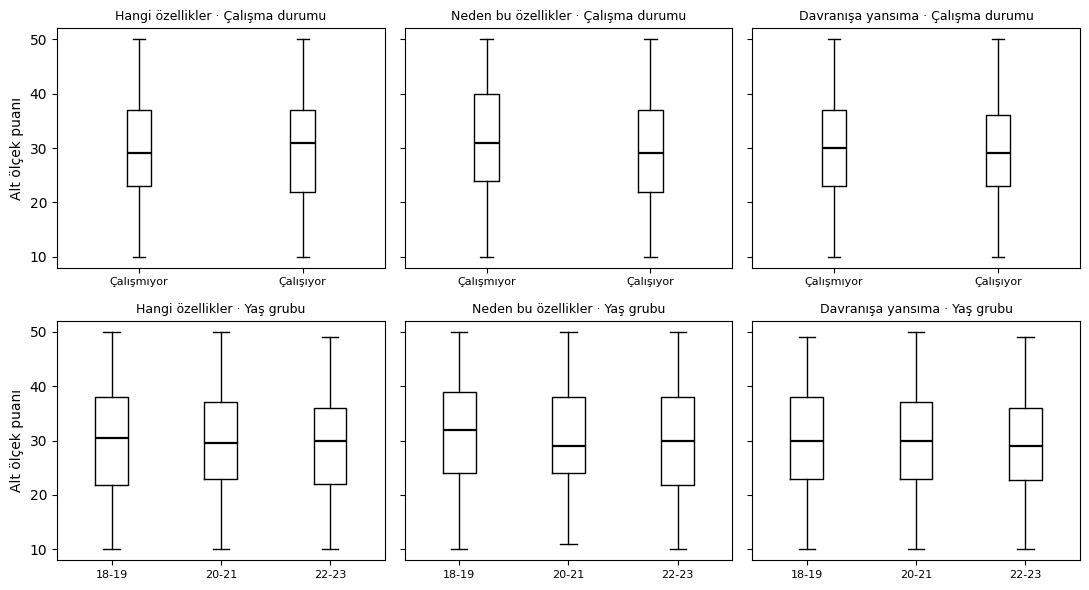


LOJİSTİK REGRESYON
Model yakınsadı: True
Model LR χ²(3) = 39.097, p = 1.65532e-08
Kare terimleri için LR testi p = 0.120744
Hangi özellikler: OR = 0.753, %95 GA [0.608, 0.931], p = 0.008866, VIF = 1.22
Neden bu özellikler: OR = 0.785, %95 GA [0.638, 0.967], p = 0.022684, VIF = 1.20
Davranışa yansıma: OR = 0.736, %95 GA [0.594, 0.911], p = 0.004937, VIF = 1.19

ROC
AUC = 0.666
Eşik kuralı: Toplam netlik ≤ 84 ise sınıf 1
Youden J = 0.287
Duyarlılık = 0.586
Özgüllük = 0.700


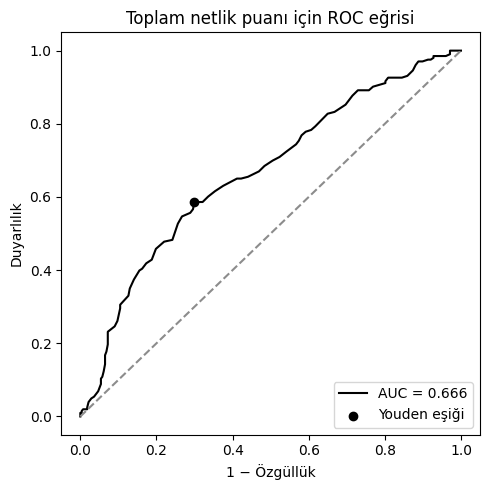


Grafiklerin kaydedildiği klasör: c:\Users\Lenovo\Desktop\Vize_Analiz


In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import chi2
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Tablo 4'te yuvarlama nedeniyle 0,050 görünen sonuç
print(f"Tablo 4, üçüncü satır, ham p = {test_tablosu.loc[2, 'p']:.8f}")

# 2. Alt ölçek puanlarının gruplara göre kutu grafikleri
adlar = ["Hangi özellikler", "Neden bu özellikler", "Davranışa yansıma"]
klasor = Path.cwd()
fig, eksenler = plt.subplots(2, 3, figsize=(11, 6), sharey=True)

for j, (sutun, ad) in enumerate(zip(alt_olcekler, adlar)):
    for i, (grup_sutunu, baslik) in enumerate([
        ("Calisma_Durumu", "Çalışma durumu"),
        ("Yas_Grubu", "Yaş grubu"),
    ]):
        gruplar = list(veri.groupby(grup_sutunu, sort=True)[sutun])
        ax = eksenler[i, j]
        ax.boxplot(
            [puanlar.to_numpy() for _, puanlar in gruplar],
            medianprops={"color": "black", "linewidth": 1.6},
        )
        ax.set_xticks(range(1, len(gruplar) + 1))
        ax.set_xticklabels([str(grup) for grup, _ in gruplar], fontsize=8)
        ax.set_title(f"{ad} · {baslik}", fontsize=9)
        if j == 0:
            ax.set_ylabel("Alt ölçek puanı")

fig.tight_layout()
fig.savefig(klasor / "sekil_2_grup_kutu_grafikleri.png", dpi=300)
plt.show()

# 3. Lojistik regresyon. OR'lar 10 puanlık artış için.
y = veri["Tercih_Catismasi"].astype(int)
puanlar = veri[list(alt_olcekler)].copy()
puanlar.columns = adlar
x = (puanlar - puanlar.mean()) / 10
X = sm.add_constant(x)
model = sm.Logit(y, X).fit(disp=False)

# Logitte doğrusallık: kare terimlerini birlikte sınama
kareler = x.pow(2).add_suffix(" kare")
genis_model = sm.Logit(y, pd.concat([X, kareler], axis=1)).fit(disp=False)
dogrusallik_p = chi2.sf(2 * (genis_model.llf - model.llf), df=x.shape[1])

print("\nLOJİSTİK REGRESYON")
print(f"Model yakınsadı: {model.mle_retvals['converged']}")
print(f"Model LR χ²({int(model.df_model)}) = {model.llr:.3f}, p = {model.llr_pvalue:.6g}")
print(f"Kare terimleri için LR testi p = {dogrusallik_p:.6f}")

guven = model.conf_int()
for j, ad in enumerate(adlar, start=1):
    alt, ust = np.exp(guven.loc[ad])
    vif = variance_inflation_factor(X.to_numpy(), j)
    print(f"{ad}: OR = {np.exp(model.params[ad]):.3f}, "
          f"%95 GA [{alt:.3f}, {ust:.3f}], "
          f"p = {model.pvalues[ad]:.6f}, VIF = {vif:.2f}")

# 4. ROC. Pozitif sınıf 1 ve düşük netlik puanı çatışma yönünde.
toplam = veri["Toplam_Netlik"]
roc_puani = -toplam
fpr, tpr, esikler = roc_curve(y, roc_puani, drop_intermediate=False)
youden = tpr - fpr
sonlu = np.flatnonzero(np.isfinite(esikler))
en_iyi = sonlu[np.argmax(youden[sonlu])]
auc = roc_auc_score(y, roc_puani)

print("\nROC")
print(f"AUC = {auc:.3f}")
print(f"Eşik kuralı: Toplam netlik ≤ {-esikler[en_iyi]:.0f} ise sınıf 1")
print(f"Youden J = {youden[en_iyi]:.3f}")
print(f"Duyarlılık = {tpr[en_iyi]:.3f}")
print(f"Özgüllük = {1 - fpr[en_iyi]:.3f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color="black", label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], "--", color="0.55")
ax.scatter(fpr[en_iyi], tpr[en_iyi], color="black", label="Youden eşiği")
ax.set(xlabel="1 − Özgüllük", ylabel="Duyarlılık", title="Toplam netlik puanı için ROC eğrisi")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(klasor / "sekil_3_roc.png", dpi=300)
plt.show()

print(f"\nGrafiklerin kaydedildiği klasör: {klasor}")